# QR Factorization Experiments — Hexagon HVX + QuRT

Sweeps three variants across matrix sizes and thread counts:

| variant | source | inparams file | threading model |
|---|---|---|---|
| `colmajor_mt`        | [qr_colmajor_mt.c](qr_colmajor_mt.c) | `build/inparams.txt`  | per-Householder `qurt_thread_create`/`join` |
| `rowmajor_mt`        | [qr_rowmajor_mt_block_alloc.c](qr_rowmajor_mt_block_alloc.c) | `build/inparams1.txt` | per-Householder spawn, row-major, mutex-protected counter |
| `pool_hh_unblocked`  | [qr_pool_hh_unblocked.c](qr_pool_hh_unblocked.c) | `build/inparams.txt`  | **persistent thread pool** (signals + atomic done-counter) |

Each binary reads its inparams file, runs HH unblocked QR on the same deterministic
input matrix (`(i*3 + j*7) % 11 - 5`), and prints cycle counts to stdout. The notebook
parses stdout, appends to `results/experiments.csv`, and produces comparison plots.

### Simulator wall-time scaling (rough)

| m=n  | wall time / run |
|------|------------------|
| 64   | ~30 s             |
| 128  | ~3 min            |
| 256  | ~20 min           |
| 512  | ~2 h              |
| 1024 | ~16 h (per run!)  |

**The default sweep below uses sizes 64/128/256 × threads 1/2/4/8** — already ~4 hours.
Set `SIZES` / `THREADS` lists at the top of the run cells to scale up or down.

In [6]:
import os, re, subprocess, time
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path('/home/vishnu/QR_factorisation')
BUILD_DIR   = PROJECT_DIR / 'build'
HEX_DIR     = BUILD_DIR / 'hexagon'
INPARAMS_DEFAULT = BUILD_DIR / 'inparams.txt'
INPARAMS_ROW     = BUILD_DIR / 'inparams1.txt'
RESULTS_DIR = PROJECT_DIR / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
CSV_PATH    = RESULTS_DIR / 'experiments.csv'

HEX_TOOLS = '/local/mnt/workspace/Qualcomm/Hexagon_SDK/6.5.0.0/tools/HEXAGON_Tools/19.0.07/Tools/bin'
ENV = os.environ.copy()
if HEX_TOOLS not in ENV.get('PATH', ''):
    ENV['PATH'] = HEX_TOOLS + ':' + ENV.get('PATH', '')

os.chdir(PROJECT_DIR)
print('Working dir:', os.getcwd())
print('CSV output :', CSV_PATH)

Working dir: /home/vishnu/QR_factorisation
CSV output : /home/vishnu/QR_factorisation/results/experiments.csv


## Variant registry + output parsers

Each variant has a different output format. The parser picks the cycle metric that
corresponds to the QR work itself (excluding setup like transpose).

In [7]:
# colmajor prints: 'Transpose cycles: N', 'QR cycles: N', 'Total cycles: N'
RX_COLMAJOR_QR = re.compile(r'^QR cycles:\s*(\d+)', re.MULTILINE)
# rowmajor prints just: 'Total cycles: N'
RX_ROWMAJOR_TOTAL = re.compile(r'^Total cycles:\s*(\d+)', re.MULTILINE)
# pool prints: '[alg] pool_hh_unblocked ... N cycles  |  max |R|-err: e  OK|FAIL'
RX_POOL_ALG = re.compile(
    r'\[alg\]\s+\S+\s+\.\.\.\s+(\d+)\s+cycles'
    r'(?:\s+\|\s+max\s+\|R\|-err:\s+([\d.eE+\-]+)\s+(OK|FAIL))?'
)
RX_POOL_REF = re.compile(
    r'\[ref\]\s+CPU\s+scalar\s+Householder\s+\.\.\.\s+(\d+)\s+cycles'
)

def parse_colmajor(text):
    m = RX_COLMAJOR_QR.search(text)
    return {'cycles': int(m.group(1)) if m else None, 'status': 'unverified', 'max_err': None}

def parse_rowmajor(text):
    m = RX_ROWMAJOR_TOTAL.search(text)
    return {'cycles': int(m.group(1)) if m else None, 'status': 'unverified', 'max_err': None}

def parse_pool(text):
    ma = RX_POOL_ALG.search(text)
    mr = RX_POOL_REF.search(text)
    return {
        'cycles':       int(ma.group(1)) if ma else None,
        'max_err':      float(ma.group(2)) if ma and ma.group(2) else None,
        'status':       (ma.group(3) if ma and ma.group(3) else 'unverified'),
        'cpu_ref_cyc':  int(mr.group(1)) if mr else None,
    }

VARIANTS = {
     'pool_hh_unblocked': {
        'build_target': 'pool',
        'sim_target':   'sim-pool',
        'inparams':     INPARAMS_DEFAULT,
        'parser':       parse_pool,
    },
    # WY-blocked: same pool output format (parse_pool), same inparams file;
    # 'nb' in inparams sets the WY block width.
    'pool_hh_wy_blocked': {
        'build_target': 'pool-wy',
        'sim_target':   'sim-pool-wy',
        'inparams':     INPARAMS_DEFAULT,
        'parser':       parse_pool,
    },
    # GEMM-based WY block update (matmul-style kernel + column blocking).
    'pool_hh_wy_gemm': {
        'build_target': 'pool-wy-gemm',
        'sim_target':   'sim-pool-wy-gemm',
        'inparams':     INPARAMS_DEFAULT,
        'parser':       parse_pool,
    },
    'colmajor_mt': {
        'build_target': 'baseline',
        'sim_target':   'sim-baseline',
        'inparams':     INPARAMS_DEFAULT,
        'parser':       parse_colmajor,
    },
    'rowmajor_mt': {
        'build_target': 'rowmajor',
        'sim_target':   'sim-rowmajor',
        'inparams':     INPARAMS_ROW,
        'parser':       parse_rowmajor,
    },
   
}
list(VARIANTS.keys())

['pool_hh_unblocked',
 'pool_hh_wy_blocked',
 'pool_hh_wy_gemm',
 'colmajor_mt',
 'rowmajor_mt']

## Helpers — write inputs, build, run sim, parse output, append to CSV

In [8]:
def write_inparams(path, m, n, nt, chunk=4, use_static=0, nb=8):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(f'{m} {n} {nt} {chunk} {use_static} {nb}\n')

def build(target):
    r = subprocess.run(['make', target], cwd=PROJECT_DIR,
                       capture_output=True, text=True, env=ENV)
    if r.returncode != 0:
        print(r.stdout[-1500:]); print(r.stderr[-1500:])
        raise RuntimeError(f'build failed: make {target}')

FIELDS = ['variant', 'm', 'n', 'nt', 'chunk', 'use_static', 'nb',
          'cycles', 'cpu_ref_cyc', 'speedup_vs_cpu', 'max_err', 'status', 'wall_seconds']

def append_csv(row):
    df_new = pd.DataFrame([row], columns=FIELDS)
    if CSV_PATH.exists():
        df_new.to_csv(CSV_PATH, mode='a', header=False, index=False)
    else:
        df_new.to_csv(CSV_PATH, mode='w', header=True, index=False)

def run_one(variant, m, n, nt, chunk=4, use_static=0, nb=8,
            timeout=72000, rebuild=False):
    """Run a single (variant, m, n, nt) sim. Returns row dict."""
    cfg = VARIANTS[variant]
    if rebuild:
        build(cfg['build_target'])
    write_inparams(cfg['inparams'], m, n, nt,
                   chunk=chunk, use_static=use_static, nb=nb)
    t0 = time.time()
    r = subprocess.run(['make', cfg['sim_target']], cwd=PROJECT_DIR,
                       capture_output=True, text=True, env=ENV, timeout=timeout)
    wall = time.time() - t0
    text = (r.stdout or '') + (r.stderr or '')
    parsed = cfg['parser'](text)
    cyc = parsed.get('cycles')
    cpu = parsed.get('cpu_ref_cyc')
    row = {
        'variant':        variant,
        'm':              m,
        'n':              n,
        'nt':             nt,
        'chunk':          chunk,
        'use_static':     use_static,
        'nb':             nb,
        'cycles':         cyc,
        'cpu_ref_cyc':    cpu,
        'speedup_vs_cpu': (cpu / cyc) if (cpu and cyc) else None,
        'max_err':        parsed.get('max_err'),
        'status':         parsed.get('status'),
        'wall_seconds':   round(wall, 1),
    }
    append_csv(row)
    print(f'  {variant:20s} m={m:4d} n={n:4d} nt={nt} | '
          f'cyc={cyc!s:>10s}  cpu={cpu!s:>10s}  '
          f'err={row["max_err"]!s:>10.10s}  {row["status"]}  ({wall:.0f}s)')
    return row

# Build all variants up front so subsequent runs are sim-only.
for v in VARIANTS:
    build(VARIANTS[v]['build_target'])
    print(f'  built: {v}')

  built: pool_hh_unblocked
  built: pool_hh_wy_blocked
  built: pool_hh_wy_gemm
  built: colmajor_mt
  built: rowmajor_mt


## Smoke test — one quick run per variant to confirm the pipeline works

If this cell fails, fix it before launching the big sweeps.

In [9]:
for v in VARIANTS:
    run_one(v, m=64, n=64, nt=4)
pd.read_csv(CSV_PATH).tail(len(VARIANTS))

  pool_hh_unblocked    m=  64 n=  64 nt=4 | cyc=    153222  cpu=    760941  err= 1.907e-05  OK  (148s)
  pool_hh_wy_blocked   m=  64 n=  64 nt=4 | cyc=    326962  cpu=    760440  err= 1.144e-05  OK  (151s)
  pool_hh_wy_gemm      m=  64 n=  64 nt=4 | cyc=    368670  cpu=    759790  err= 1.144e-05  OK  (154s)
  colmajor_mt          m=  64 n=  64 nt=4 | cyc=    766529  cpu=      None  err=      None  unverified  (249s)
  rowmajor_mt          m=  64 n=  64 nt=4 | cyc=    414839  cpu=      None  err=      None  unverified  (219s)


,variant,m,n,nt,chunk,use_static,nb,cycles,cpu_ref_cyc,speedup_vs_cpu,max_err,status,wall_seconds
84,pool_hh_unblocked,64,64,4,4,0,8,153222,760941.0,4.966265,0.000019,OK,147.9
85,pool_hh_wy_blocked,64,64,4,4,0,8,326962,760440.0,2.325775,0.000011,OK,151.3
86,pool_hh_wy_gemm,64,64,4,4,0,8,368670,759790.0,2.060895,0.000011,OK,154.1
87,colmajor_mt,64,64,4,4,0,8,766529,NaN,NaN,NaN,unverified,249.1
88,rowmajor_mt,64,64,4,4,0,8,414839,NaN,NaN,NaN,unverified,219.0


## Experiment 1 — Matrix-size sweep at fixed thread count

How do the variants scale with `n` when thread count is held fixed?

Edit `SIZES_EXP1` / `NT_EXP1` to control the sweep. Default is light;
uncomment the heavy sizes once you've verified the light sweep finishes.

In [10]:
SIZES_EXP1 = [64, 128, 256, 512, 1024,1536,2048]          # add 512, 1024 for the full sweep
NT_EXP1    = 4

for m in SIZES_EXP1:
    for v in VARIANTS:
        try:
            run_one(v, m=m, n=m, nt=NT_EXP1)
        except subprocess.TimeoutExpired:
            print(f'  TIMEOUT: {v} m={m}'); break
        except Exception as e:
            print(f'  FAIL: {v} m={m} -> {e}')

df = pd.read_csv(CSV_PATH)
df.tail(len(SIZES_EXP1) * len(VARIANTS))

  pool_hh_unblocked    m=  64 n=  64 nt=4 | cyc=    160818  cpu=    760941  err= 1.907e-05  OK  (150s)
  pool_hh_wy_blocked   m=  64 n=  64 nt=4 | cyc=    327316  cpu=    760440  err= 1.144e-05  OK  (155s)
  pool_hh_wy_gemm      m=  64 n=  64 nt=4 | cyc=    373391  cpu=    759790  err= 1.144e-05  OK  (154s)
  colmajor_mt          m=  64 n=  64 nt=4 | cyc=    773482  cpu=      None  err=      None  unverified  (245s)
  rowmajor_mt          m=  64 n=  64 nt=4 | cyc=    414839  cpu=      None  err=      None  unverified  (219s)
  pool_hh_unblocked    m= 128 n= 128 nt=4 | cyc=    341377  cpu=   3805106  err= 1.717e-05  OK  (177s)
  pool_hh_wy_blocked   m= 128 n= 128 nt=4 | cyc=   1153319  cpu=   3803262  err=  2.48e-05  OK  (189s)
  pool_hh_wy_gemm      m= 128 n= 128 nt=4 | cyc=   1301460  cpu=   3802474  err=  2.48e-05  OK  (194s)
  colmajor_mt          m= 128 n= 128 nt=4 | cyc=   1162806  cpu=      None  err=      None  unverified  (277s)
  rowmajor_mt          m= 128 n= 128 nt=4 | cyc= 

KeyboardInterrupt: 

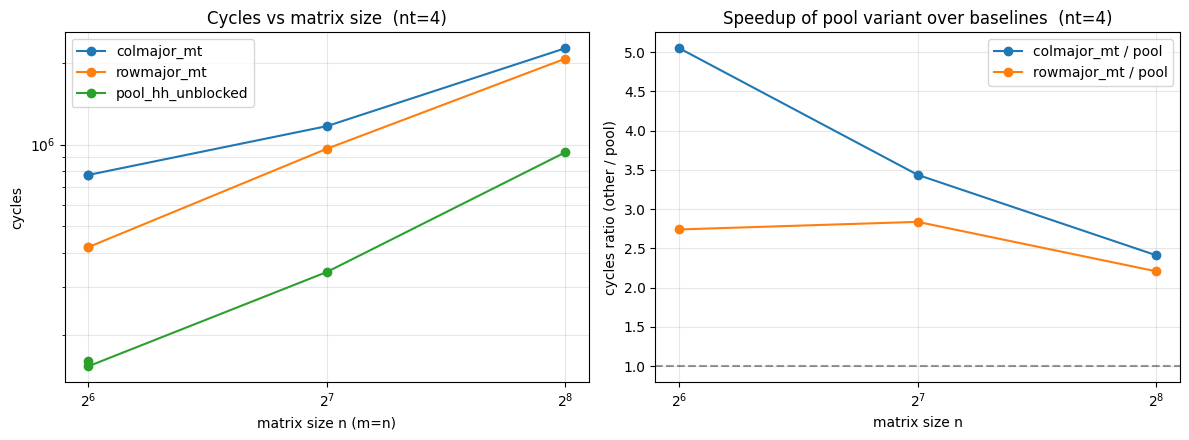

In [ ]:
# Plot: cycles vs matrix size, one line per variant (log-log).
df = pd.read_csv(CSV_PATH)
df1 = df[df['nt'] == NT_EXP1].dropna(subset=['cycles'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
for v in VARIANTS:
    sub = df1[df1['variant'] == v].sort_values('m')
    if not sub.empty:
        ax.plot(sub['m'], sub['cycles'], marker='o', label=v)
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xlabel('matrix size n (m=n)'); ax.set_ylabel('cycles')
ax.set_title(f'Cycles vs matrix size  (nt={NT_EXP1})')
ax.grid(True, which='both', alpha=0.3); ax.legend()

# Speedup of pool vs colmajor and rowmajor.
ax = axes[1]
pivot = df1.pivot_table(index='m', columns='variant', values='cycles', aggfunc='last')
if 'pool_hh_unblocked' in pivot.columns:
    for other in [c for c in pivot.columns if c != 'pool_hh_unblocked']:
        ratio = pivot[other] / pivot['pool_hh_unblocked']
        ax.plot(ratio.index, ratio.values, marker='o', label=f'{other} / pool')
    ax.axhline(1.0, color='k', linestyle='--', alpha=0.4)
    ax.set_xscale('log', base=2)
    ax.set_xlabel('matrix size n'); ax.set_ylabel('cycles ratio (other / pool)')
    ax.set_title(f'Speedup of pool variant over baselines  (nt={NT_EXP1})')
    ax.grid(True, alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'exp1_size_sweep.png', dpi=120)
plt.show()

## Experiment 2 — Thread-count sweep at fixed matrix size

How does each variant scale from 1 thread to 8 threads?

In [ ]:
M_EXP2     = 256                    # fixed matrix size
THREADS_EXP2 = [1,2,3,4,5,6,7,8]

for nt in THREADS_EXP2:
    for v in VARIANTS:
        try:
            run_one(v, m=M_EXP2, n=M_EXP2, nt=nt)
        except Exception as e:
            print(f'  FAIL: {v} nt={nt} -> {e}')

df = pd.read_csv(CSV_PATH)
df.tail(len(THREADS_EXP2) * len(VARIANTS))

  colmajor_mt          m= 256 n= 256 nt=1 | cyc=   4138844  cpu=      None  err=      None  unverified  (211s)
  rowmajor_mt          m= 256 n= 256 nt=1 | cyc=   2513564  cpu=      None  err=      None  unverified  (224s)
  pool_hh_unblocked    m= 256 n= 256 nt=1 | cyc=   2618262  cpu=  21008896  err= 4.959e-05  OK  (361s)
  colmajor_mt          m= 256 n= 256 nt=2 | cyc=   2623851  cpu=      None  err=      None  unverified  (279s)
  rowmajor_mt          m= 256 n= 256 nt=2 | cyc=   1941270  cpu=      None  err=      None  unverified  (295s)
  pool_hh_unblocked    m= 256 n= 256 nt=2 | cyc=   1474181  cpu=  21008896  err= 4.959e-05  OK  (358s)
  colmajor_mt          m= 256 n= 256 nt=3 | cyc=   2303629  cpu=      None  err=      None  unverified  (326s)
  rowmajor_mt          m= 256 n= 256 nt=3 | cyc=   2018950  cpu=      None  err=      None  unverified  (345s)
  pool_hh_unblocked    m= 256 n= 256 nt=3 | cyc=   1106509  cpu=  21008896  err= 4.959e-05  OK  (354s)
  colmajor_mt          m=

,variant,m,n,nt,chunk,use_static,nb,cycles,cpu_ref_cyc,speedup_vs_cpu,max_err,status,wall_seconds
12,colmajor_mt,256,256,1,4,0,8,4138844,NaN,NaN,NaN,unverified,211.0
13,rowmajor_mt,256,256,1,4,0,8,2513564,NaN,NaN,NaN,unverified,223.6
14,pool_hh_unblocked,256,256,1,4,0,8,2618262,21008896.0,8.023985,0.00005,OK,361.1
15,colmajor_mt,256,256,2,4,0,8,2623851,NaN,NaN,NaN,unverified,278.9
16,rowmajor_mt,256,256,2,4,0,8,1941270,NaN,NaN,NaN,unverified,295.5
17,pool_hh_unblocked,256,256,2,4,0,8,1474181,21008896.0,14.251232,0.00005,OK,358.1
18,colmajor_mt,256,256,3,4,0,8,2303629,NaN,NaN,NaN,unverified,325.5
19,rowmajor_mt,256,256,3,4,0,8,2018950,NaN,NaN,NaN,unverified,345.4
20,pool_hh_unblocked,256,256,3,4,0,8,1106509,21008896.0,18.986647,0.00005,OK,353.7
21,colmajor_mt,256,256,4,4,0,8,2250425,NaN,NaN,NaN,unverified,364.7


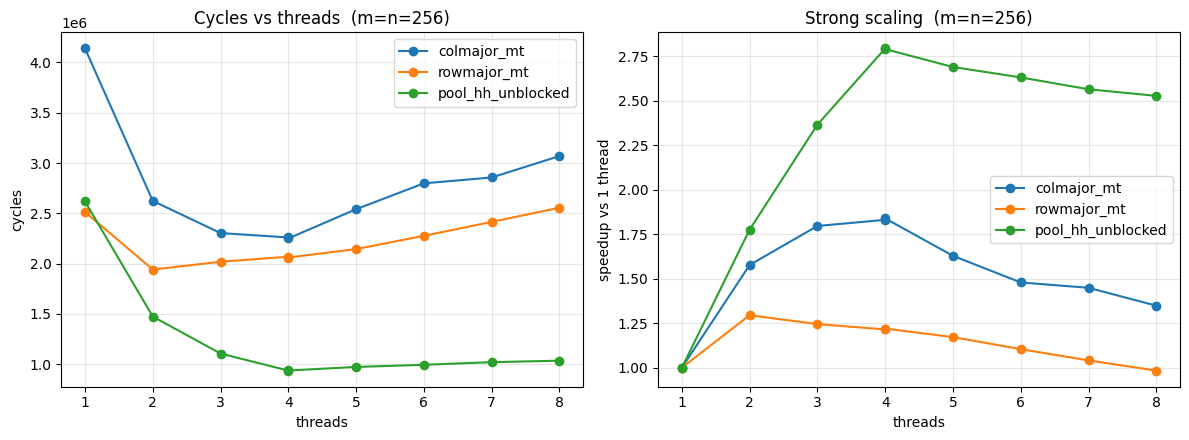

In [ ]:
df = pd.read_csv(CSV_PATH)
df2 = df[(df['m'] == M_EXP2) & df['cycles'].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
for v in VARIANTS:
    sub = df2[df2['variant'] == v].sort_values('nt')
    if not sub.empty:
        ax.plot(sub['nt'], sub['cycles'], marker='o', label=v)
ax.set_xticks(THREADS_EXP2)
ax.set_xlabel('threads'); ax.set_ylabel('cycles')
ax.set_title(f'Cycles vs threads  (m=n={M_EXP2})')
ax.grid(True, alpha=0.3); ax.legend()

# Strong-scaling speedup vs nt=1
ax = axes[1]
for v in VARIANTS:
    sub = df2[df2['variant'] == v].sort_values('nt')
    if sub.empty: continue
    base = sub[sub['nt'] == 1]
    if base.empty: continue
    base_cyc = base.iloc[0]['cycles']
    ax.plot(sub['nt'], base_cyc / sub['cycles'], marker='o', label=v)
# ax.plot(THREADS_EXP2, THREADS_EXP2, color='k', linestyle='--', alpha=0.4, label='ideal linear')
ax.set_xticks(THREADS_EXP2)
ax.set_xlabel('threads'); ax.set_ylabel('speedup vs 1 thread')
ax.set_title(f'Strong scaling  (m=n={M_EXP2})')
ax.grid(True, alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'exp2_thread_sweep.png', dpi=120)
plt.show()

## Experiment 3 — Full grid (size × threads × variant)

**Expensive.** Default keeps it modest; uncomment additional sizes/threads when ready.
Per-variant heatmap shows cycles across the (size, threads) plane.

Skip rows already in the CSV so re-runs only fill the holes.

In [ ]:
SIZES_EXP3   = [64, 128, 256]               # add 512, 1024 if you have hours
THREADS_EXP3 = [1, 2, 4, 8]

existing = set()
if CSV_PATH.exists():
    df_prev = pd.read_csv(CSV_PATH)
    existing = set(zip(df_prev['variant'], df_prev['m'], df_prev['n'], df_prev['nt']))

to_run = [(v, m, nt)
          for v in VARIANTS for m in SIZES_EXP3 for nt in THREADS_EXP3
          if (v, m, m, nt) not in existing]
print(f'planned: {len(to_run)} runs (skipping {len(SIZES_EXP3)*len(THREADS_EXP3)*len(VARIANTS) - len(to_run)} already done)')

for v, m, nt in to_run:
    try:
        run_one(v, m=m, n=m, nt=nt)
    except Exception as e:
        print(f'  FAIL: {v} m={m} nt={nt} -> {e}')

df = pd.read_csv(CSV_PATH)
df.tail(20)

planned: 18 runs (skipping 18 already done)
  colmajor_mt          m=  64 n=  64 nt=1 | cyc=    630174  cpu=      None  err=      None  unverified  (179s)
  colmajor_mt          m=  64 n=  64 nt=2 | cyc=    581674  cpu=      None  err=      None  unverified  (206s)
  colmajor_mt          m=  64 n=  64 nt=8 | cyc=   1188780  cpu=      None  err=      None  unverified  (382s)
  colmajor_mt          m= 128 n= 128 nt=1 | cyc=   1442726  cpu=      None  err=      None  unverified  (186s)
  colmajor_mt          m= 128 n= 128 nt=2 | cyc=   1055248  cpu=      None  err=      None  unverified  (243s)
  colmajor_mt          m= 128 n= 128 nt=8 | cyc=   1689349  cpu=      None  err=      None  unverified  (433s)
  rowmajor_mt          m=  64 n=  64 nt=1 | cyc=    343914  cpu=      None  err=      None  unverified  (201s)
  rowmajor_mt          m=  64 n=  64 nt=2 | cyc=    414839  cpu=      None  err=      None  unverified  (248s)
  rowmajor_mt          m=  64 n=  64 nt=8 | cyc=    414839  cpu=    

,variant,m,n,nt,chunk,use_static,nb,cycles,cpu_ref_cyc,speedup_vs_cpu,max_err,status,wall_seconds
34,rowmajor_mt,256,256,8,4,0,8,2555786,NaN,NaN,NaN,unverified,554.0
35,pool_hh_unblocked,256,256,8,4,0,8,1035653,21008896.0,20.285652,0.000050,OK,361.4
36,colmajor_mt,64,64,1,4,0,8,630174,NaN,NaN,NaN,unverified,179.4
37,colmajor_mt,64,64,2,4,0,8,581674,NaN,NaN,NaN,unverified,205.7
38,colmajor_mt,64,64,8,4,0,8,1188780,NaN,NaN,NaN,unverified,381.6
39,colmajor_mt,128,128,1,4,0,8,1442726,NaN,NaN,NaN,unverified,185.9
40,colmajor_mt,128,128,2,4,0,8,1055248,NaN,NaN,NaN,unverified,243.3
41,colmajor_mt,128,128,8,4,0,8,1689349,NaN,NaN,NaN,unverified,432.5
42,rowmajor_mt,64,64,1,4,0,8,343914,NaN,NaN,NaN,unverified,200.7
43,rowmajor_mt,64,64,2,4,0,8,414839,NaN,NaN,NaN,unverified,247.8


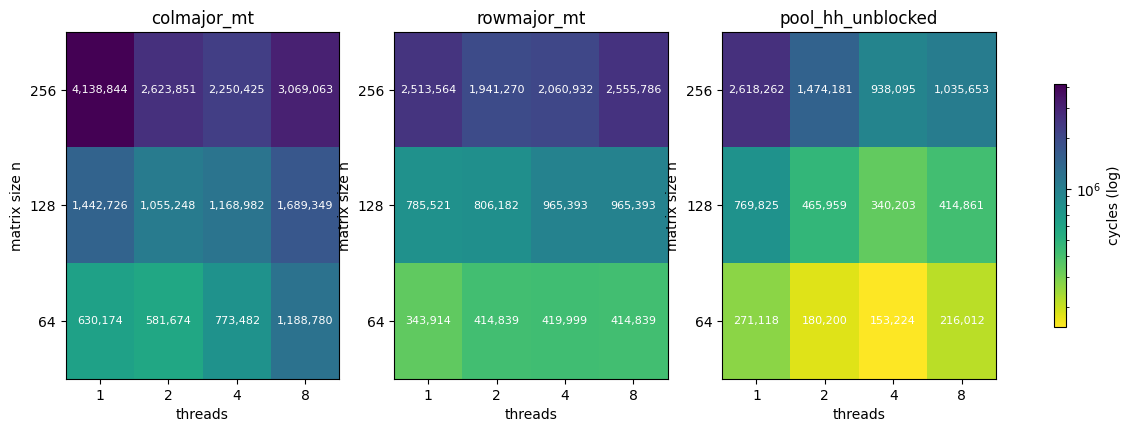

In [ ]:
# Per-variant heatmap of cycles across (matrix size, threads).
df = pd.read_csv(CSV_PATH).dropna(subset=['cycles'])
df = df[df['m'].isin(SIZES_EXP3) & df['nt'].isin(THREADS_EXP3)]

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(5 * len(VARIANTS), 4.5))
if len(VARIANTS) == 1: axes = [axes]

# Use a global cycle range so the colour scale is comparable.
vmax = df['cycles'].max()
vmin = df['cycles'].min()

for ax, v in zip(axes, VARIANTS):
    sub = df[df['variant'] == v]
    grid = sub.pivot_table(index='m', columns='nt', values='cycles', aggfunc='last')
    grid = grid.reindex(index=sorted(SIZES_EXP3, reverse=True), columns=sorted(THREADS_EXP3))
    im = ax.imshow(grid.values, aspect='auto', cmap='viridis_r',
                   norm=plt.matplotlib.colors.LogNorm(vmin=max(1, vmin), vmax=vmax))
    ax.set_xticks(range(len(grid.columns))); ax.set_xticklabels(grid.columns)
    ax.set_yticks(range(len(grid.index)));   ax.set_yticklabels(grid.index)
    ax.set_xlabel('threads'); ax.set_ylabel('matrix size n')
    ax.set_title(v)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            val = grid.values[i, j]
            if pd.notna(val):
                ax.text(j, i, f'{int(val):,}', ha='center', va='center',
                        color='white', fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.7, label='cycles (log)')
fig.savefig(RESULTS_DIR / 'exp3_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

## Summary tables

Best variant per (size, threads) and overall ranking.

In [ ]:
df = pd.read_csv(CSV_PATH).dropna(subset=['cycles'])

# Best variant per (m, nt)
best = df.sort_values('cycles').groupby(['m', 'nt']).first().reset_index()
print('--- Best variant per (m, nt) ---')
print(best[['m', 'nt', 'variant', 'cycles', 'status']].to_string(index=False))

# Pivot: cycles per variant at each (m, nt)
print('\n--- Cycles by variant (rows = m, cols = nt) ---')
for v in VARIANTS:
    sub = df[df['variant'] == v]
    if sub.empty: continue
    print(f'\n[{v}]')
    pivot = sub.pivot_table(index='m', columns='nt', values='cycles', aggfunc='last')
    print(pivot.to_string())

# Speedup of pool over col/row at each (m, nt)
print('\n--- Speedup: other / pool_hh_unblocked ---')
pool = df[df['variant'] == 'pool_hh_unblocked'][['m', 'nt', 'cycles']].rename(
    columns={'cycles': 'pool_cyc'})
for v in [x for x in VARIANTS if x != 'pool_hh_unblocked']:
    sub = df[df['variant'] == v][['m', 'nt', 'cycles']].merge(pool, on=['m', 'nt'])
    sub['speedup'] = sub['cycles'] / sub['pool_cyc']
    print(f'\n[{v} / pool]')
    print(sub.pivot_table(index='m', columns='nt', values='speedup', aggfunc='last').to_string(float_format='%.2fx'))

--- Best variant per (m, nt) ---
  m  nt           variant  cycles     status
 64   1 pool_hh_unblocked  271118         OK
 64   2 pool_hh_unblocked  180200         OK
 64   4 pool_hh_unblocked  153224         OK
 64   8 pool_hh_unblocked  216012         OK
128   1 pool_hh_unblocked  769825         OK
128   2 pool_hh_unblocked  465959         OK
128   4 pool_hh_unblocked  340203         OK
128   8 pool_hh_unblocked  414861         OK
256   1       rowmajor_mt 2513564 unverified
256   2 pool_hh_unblocked 1474181         OK
256   3 pool_hh_unblocked 1106509         OK
256   4 pool_hh_unblocked  936881         OK
256   5 pool_hh_unblocked  973203         OK
256   6 pool_hh_unblocked  994865         OK
256   7 pool_hh_unblocked 1020741         OK
256   8 pool_hh_unblocked 1035653         OK

--- Cycles by variant (rows = m, cols = nt) ---

[colmajor_mt]
nt           1          2          3          4          5          6          7          8
m                                             